In [1]:

import os

print("Checking files in Colab...")

print("Files in /content:")
print(os.listdir("/content"))


Checking files in Colab...
Files in /content:
['.config', 'sample_data']


In [2]:

import os

project_path = "/content/Parking_Slot_Occupancy_Detection"

os.makedirs(project_path, exist_ok=True)
os.makedirs(os.path.join(project_path, "dataset"), exist_ok=True)
os.makedirs(os.path.join(project_path, "results"), exist_ok=True)

print("Project folder created successfully!")
print("Project location:", project_path)
print("Folders:", os.listdir(project_path))


Project folder created successfully!
Project location: /content/Parking_Slot_Occupancy_Detection
Folders: ['results', 'dataset']


In [3]:

import os

project_path = "/content/Parking_Slot_Occupancy_Detection"
dataset_path = os.path.join(project_path, "dataset")

os.makedirs(dataset_path, exist_ok=True)

print("Project ready:", os.path.exists(project_path))
print("Dataset folder ready:", os.path.exists(dataset_path))
print("Dataset folder contents:", os.listdir(dataset_path))


Project ready: True
Dataset folder ready: True
Dataset folder contents: []


In [4]:

import os
import urllib.request

project_path = "/content/Parking_Slot_Occupancy_Detection"
dataset_path = os.path.join(project_path, "dataset")

url = "https://rmit.figshare.com/ndownloader/files/24753887"
zip_path = os.path.join(dataset_path, "parking_sample.zip")

print("Downloading parking dataset...")
urllib.request.urlretrieve(url, zip_path)

print("Download complete!")
print("File size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))


Download complete!
File size (MB): 0.0


In [7]:

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)


Saving archive (5).zip to archive (5).zip

Uploaded files:
archive (5).zip


In [8]:

import os
import zipfile

zip_path = "/content/archive (5).zip"
dataset_path = "/content/Parking_Slot_Occupancy_Detection/dataset"

os.makedirs(dataset_path, exist_ok=True)

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(dataset_path)

    print("Dataset extracted successfully!")
    print("Dataset location:", dataset_path)
    print("\nFiles and folders inside dataset:")

    for item in os.listdir(dataset_path)[:30]:
        print(item)
else:
    print("ZIP file not found. Please upload it again.")


Dataset extracted successfully!
Dataset location: /content/Parking_Slot_Occupancy_Detection/dataset

Files and folders inside dataset:
124.jpg
123.jpg
166.json
29.json
154.jpg
126.jpg
36.jpg
109.jpg
120.jpg
37.json
64.jpg
106.json
49.jpg
63.json
60.json
152.jpg
79.json
92.jpg
30.jpg
38.jpg
103.json
61.jpg
78.json
136.json
71.json
156.jpg
111.jpg
74.jpg
111.json
155.json


In [9]:

import os
import json

dataset_path = "/content/Parking_Slot_Occupancy_Detection/dataset"

files = os.listdir(dataset_path)

images = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
json_files = [f for f in files if f.lower().endswith(".json")]

print("Total images:", len(images))
print("Total JSON files:", len(json_files))

print("\nSample images:", images[:5])
print("Sample JSON files:", json_files[:5])

if json_files:
    json_path = os.path.join(dataset_path, json_files[0])

    with open(json_path, "r") as f:
        data = json.load(f)

    print("\nExample annotation file:", json_files[0])
    print(json.dumps(data, indent=2)[:2500])


Total images: 150
Total JSON files: 150

Sample images: ['124.jpg', '123.jpg', '154.jpg', '126.jpg', '36.jpg']
Sample JSON files: ['166.json', '29.json', '37.json', '106.json', '63.json']

Example annotation file: 166.json
{
  "labels": [
    {
      "name": "Occupied",
      "x1": 212,
      "y1": 3,
      "x2": 266,
      "y2": 106
    },
    {
      "name": "Occupied",
      "x1": 159,
      "y1": 3,
      "x2": 212,
      "y2": 107
    },
    {
      "name": "Occupied",
      "x1": 529,
      "y1": 3,
      "x2": 581,
      "y2": 105
    },
    {
      "name": "Occupied",
      "x1": 318,
      "y1": 3,
      "x2": 371,
      "y2": 106
    },
    {
      "name": "Occupied",
      "x1": 371,
      "y1": 3,
      "x2": 423,
      "y2": 106
    },
    {
      "name": "Occupied",
      "x1": 1,
      "y1": 3,
      "x2": 54,
      "y2": 108
    },
    {
      "name": "Occupied",
      "x1": 688,
      "y1": 3,
      "x2": 740,
      "y2": 105
    },
    {
      "name": "Occupied",
    

In [10]:

import os
import json
from collections import Counter

dataset_path = "/content/Parking_Slot_Occupancy_Detection/dataset"

image_names = {
    os.path.splitext(f)[0]
    for f in os.listdir(dataset_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

json_names = {
    os.path.splitext(f)[0]
    for f in os.listdir(dataset_path)
    if f.lower().endswith(".json")
}

print("Images:", len(image_names))
print("JSON files:", len(json_names))
print("Images without JSON:", sorted(image_names - json_names)[:10])
print("JSON without images:", sorted(json_names - image_names)[:10])

counts = Counter()
total_boxes = 0
invalid_files = []

for name in sorted(image_names & json_names):
    json_path = os.path.join(dataset_path, name + ".json")

    try:
        with open(json_path, "r") as f:
            data = json.load(f)

        for label in data.get("labels", []):
            counts[label.get("name", "Unknown")] += 1
            total_boxes += 1
    except Exception as e:
        invalid_files.append((name, str(e)))

print("\nParking slot annotation counts:")
for label, count in counts.items():
    print(f"{label}: {count}")

print("Total annotated slots:", total_boxes)
print("Invalid JSON files:", len(invalid_files))


Images: 150
JSON files: 150
Images without JSON: []
JSON without images: []

Parking slot annotation counts:
Occupied: 2443
Vacant: 318
Total annotated slots: 2761
Invalid JSON files: 0


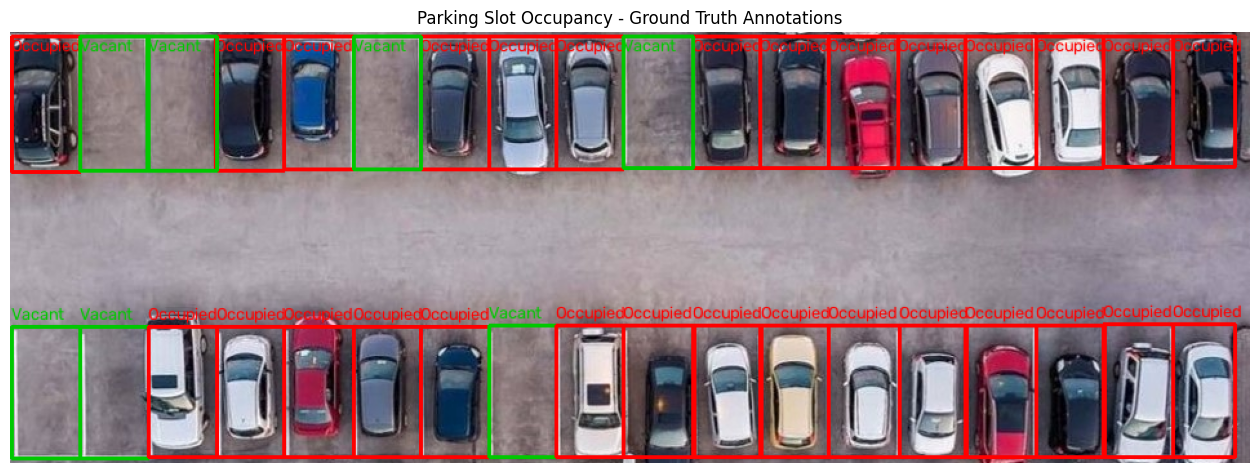

In [11]:

import os
import json
import cv2
import matplotlib.pyplot as plt

dataset_path = "/content/Parking_Slot_Occupancy_Detection/dataset"

image_name = "166.jpg"
image_path = os.path.join(dataset_path, image_name)
json_path = os.path.join(dataset_path, "166.json")

image = cv2.imread(image_path)

if image is None:
    print("Image not found:", image_path)
else:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    with open(json_path, "r") as f:
        annotations = json.load(f)

    for label in annotations["labels"]:
        x1 = int(label["x1"])
        y1 = int(label["y1"])
        x2 = int(label["x2"])
        y2 = int(label["y2"])
        name = label["name"]

        color = (255, 0, 0) if name == "Occupied" else (0, 200, 0)

        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
        cv2.putText(
            image, name, (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1
        )

    plt.figure(figsize=(16, 8))
    plt.imshow(image)
    plt.title("Parking Slot Occupancy - Ground Truth Annotations")
    plt.axis("off")
    plt.show()


In [12]:

import os
import json
import cv2
import random
import shutil

# Project folders
project_path = "/content/Parking_Slot_Occupancy_Detection"
dataset_path = os.path.join(project_path, "dataset")
yolo_path = os.path.join(project_path, "yolo_dataset")

# Create YOLO dataset folders
for folder in [
    "images/train",
    "images/val",
    "labels/train",
    "labels/val"
]:
    os.makedirs(os.path.join(yolo_path, folder), exist_ok=True)

# Class mapping
class_map = {
    "Occupied": 0,
    "Vacant": 1
}

# Find images with matching JSON annotations
image_files = sorted([
    f for f in os.listdir(dataset_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
    and os.path.exists(
        os.path.join(dataset_path, os.path.splitext(f)[0] + ".json")
    )
])

random.seed(42)
random.shuffle(image_files)

# 80% training, 20% validation
split_index = int(len(image_files) * 0.8)
train_files = image_files[:split_index]
val_files = image_files[split_index:]

def convert_files(file_list, split):
    for filename in file_list:
        image_path = os.path.join(dataset_path, filename)
        json_path = os.path.join(
            dataset_path, os.path.splitext(filename)[0] + ".json"
        )

        image = cv2.imread(image_path)
        if image is None:
            print("Skipping unreadable image:", filename)
            continue

        height, width = image.shape[:2]

        with open(json_path, "r") as f:
            data = json.load(f)

        yolo_lines = []

        for label in data.get("labels", []):
            name = label.get("name")

            if name not in class_map:
                continue

            x1 = max(0, min(float(label["x1"]), width))
            y1 = max(0, min(float(label["y1"]), height))
            x2 = max(0, min(float(label["x2"]), width))
            y2 = max(0, min(float(label["y2"]), height))

            box_width = x2 - x1
            box_height = y2 - y1

            if box_width <= 0 or box_height <= 0:
                continue

            x_center = ((x1 + x2) / 2) / width
            y_center = ((y1 + y2) / 2) / height
            norm_width = box_width / width
            norm_height = box_height / height

            yolo_lines.append(
                f"{class_map[name]} {x_center:.6f} "
                f"{y_center:.6f} {norm_width:.6f} {norm_height:.6f}"
            )

        # Copy image and save corresponding YOLO labels
        shutil.copy2(
            image_path,
            os.path.join(yolo_path, "images", split, filename)
        )

        label_filename = os.path.splitext(filename)[0] + ".txt"
        with open(
            os.path.join(yolo_path, "labels", split, label_filename), "w"
        ) as f:
            f.write("\n".join(yolo_lines))

convert_files(train_files, "train")
convert_files(val_files, "val")

print("YOLO conversion complete!")
print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("YOLO dataset:", yolo_path)
print("Classes:", class_map)


YOLO conversion complete!
Training images: 120
Validation images: 30
YOLO dataset: /content/Parking_Slot_Occupancy_Detection/yolo_dataset
Classes: {'Occupied': 0, 'Vacant': 1}


In [13]:

import os
import yaml

project_path = "/content/Parking_Slot_Occupancy_Detection"
yolo_path = os.path.join(project_path, "yolo_dataset")

config = {
    "path": yolo_path,
    "train": "images/train",
    "val": "images/val",
    "names": {
        0: "Occupied",
        1: "Vacant"
    }
}

yaml_path = os.path.join(project_path, "data.yaml")

with open(yaml_path, "w") as f:
    yaml.dump(config, f, sort_keys=False)

print("YOLO configuration created!")
print("Location:", yaml_path)

with open(yaml_path, "r") as f:
    print("\nConfiguration contents:\n")
    print(f.read())


YOLO configuration created!
Location: /content/Parking_Slot_Occupancy_Detection/data.yaml

Configuration contents:

path: /content/Parking_Slot_Occupancy_Detection/yolo_dataset
train: images/train
val: images/val
names:
  0: Occupied
  1: Vacant



In [14]:

%pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 9.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [15]:

import torch
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. We can train using the CPU.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.189
PyTorch version: 2.11.0+cpu
CUDA available: False
No GPU detected. We can train using the CPU.


In [16]:

from ultralytics import YOLO
import os

project_path = "/content/Parking_Slot_Occupancy_Detection"
data_yaml = os.path.join(project_path, "data.yaml")

# Load a small pretrained YOLO model
model = YOLO("yolo11n.pt")

# Train using your dataset
results = model.train(
    data=data_yaml,
    epochs=10,
    imgsz=640,
    batch=4,
    device="cpu",
    workers=2,
    project=project_path,
    name="parking_training",
    exist_ok=True
)

print("Training finished!")


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Parking_Slot_Occupancy_Detection/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=parking_training, nbs=64, nms=None, opset=None,


image 1/1 /content/Parking_Slot_Occupancy_Detection/yolo_dataset/images/val/126.jpg: 480x640 29 Occupieds, 113.0ms
Speed: 2.3ms preprocess, 113.0ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/Parking_Slot_Occupancy_Detection/results/test_detection
Test image: /content/Parking_Slot_Occupancy_Detection/yolo_dataset/images/val/126.jpg
Detection result saved in: /content/Parking_Slot_Occupancy_Detection/results/test_detection
Detected parking slots: 29


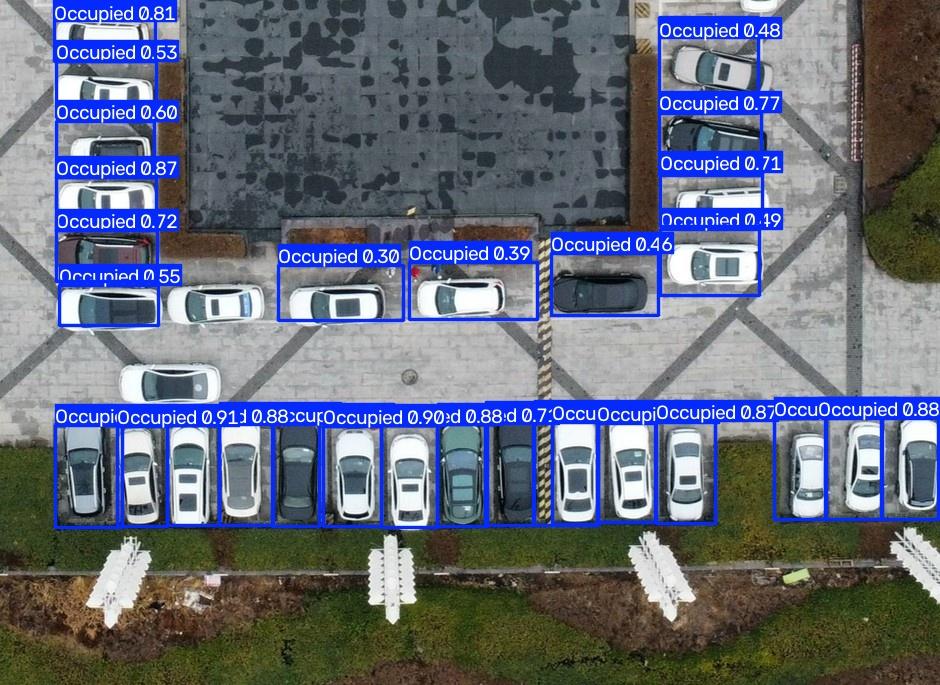

In [17]:

import os
import random
import glob
from ultralytics import YOLO
from IPython.display import display, Image

project_path = "/content/Parking_Slot_Occupancy_Detection"

# Load the trained model
model_path = os.path.join(
    project_path, "parking_training", "weights", "best.pt"
)
model = YOLO(model_path)

# Select one validation image
val_images = glob.glob(
    os.path.join(project_path, "yolo_dataset", "images", "val", "*")
)

image_path = random.choice(val_images)

# Run detection
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True,
    project=os.path.join(project_path, "results"),
    name="test_detection",
    exist_ok=True
)

# Display the detected image
output_path = results[0].save_dir
saved_image = os.path.join(output_path, os.path.basename(image_path))

print("Test image:", image_path)
print("Detection result saved in:", output_path)
print("Detected parking slots:", len(results[0].boxes))

display(Image(filename=saved_image))


Prediction images found: ['126.jpg']


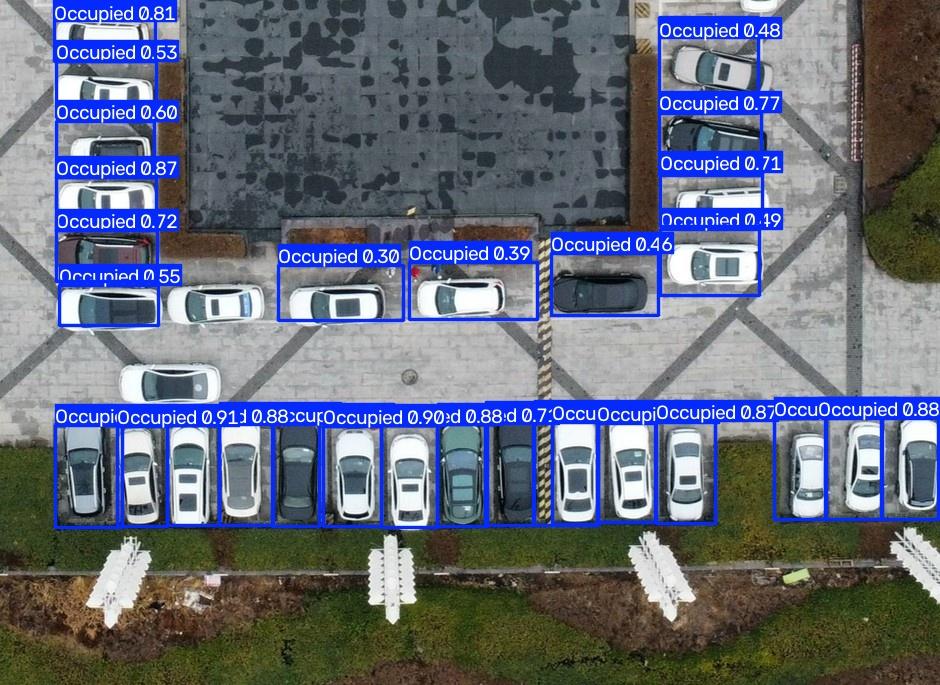

In [18]:
import os
from IPython.display import display, Image

result_folder = "/content/Parking_Slot_Occupancy_Detection/results/test_detection"

images = [
    f for f in os.listdir(result_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Prediction images found:", images)

if images:
    display(Image(filename=os.path.join(result_folder, images[0])))
else:
    print("No prediction image found in the folder.")

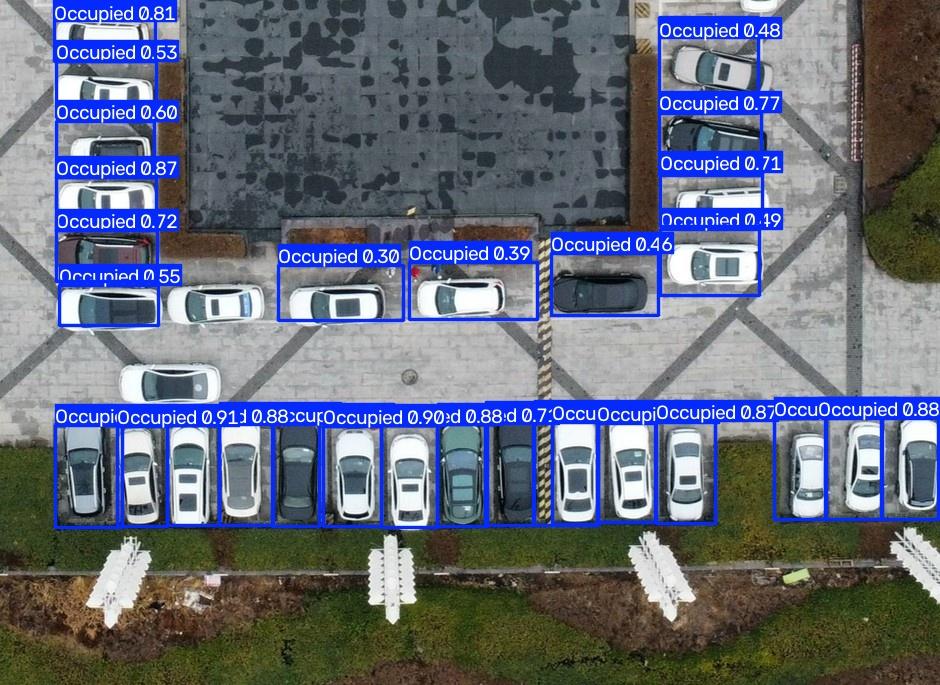

In [19]:
from IPython.display import display, Image

image_path = "/content/Parking_Slot_Occupancy_Detection/results/test_detection/126.jpg"

display(Image(filename=image_path))

In [20]:
import os

project_path = "/content/Parking_Slot_Occupancy_Detection"
readme_path = os.path.join(project_path, "README.md")

readme_content = """# Parking Slot Occupancy Detection

## Project Overview
This project uses YOLO object detection to identify parking slots
as Occupied or Vacant from parking lot images.

## Technologies Used
- Python
- Ultralytics YOLO11
- PyTorch
- OpenCV
- Google Colab

## Dataset
The dataset contains 150 images with JSON annotations.

The annotations were converted into YOLO format and divided into:
- Training: 120 images
- Validation: 30 images

## Classes
- Occupied (class 0)
- Vacant (class 1)

## Model Training
- Model: YOLO11n
- Image size: 640
- Epochs: 10
- Training device: CPU

## Validation Results
- Precision: 0.892
- Recall: 0.913
- mAP@50: 0.937
- mAP@50-95: 0.751

These metrics were measured on a validation set of 30 images.
Results may vary on new images.

## Test
The trained model was tested on a validation image.
One test image produced 29 detections classified as Occupied.

## Main Files
- parking_training/weights/best.pt: trained model
- data.yaml: dataset configuration
- results/test_detection/: prediction output
- README.md: project documentation

## How to Load the Model
```python
from ultralytics import YOLO

model = YOLO("best.pt")
results = model.predict("parking_image.jpg", save=True)

_IncompleteInputError: incomplete input (2789579807.py, line 6)

In [21]:
import os

project_path = "/content/Parking_Slot_Occupancy_Detection"
os.makedirs(project_path, exist_ok=True)

readme_content = '''# Parking Slot Occupancy Detection

## Project Overview
This project uses YOLO11 object detection to classify parking spaces
as Occupied or Vacant in parking lot images.

## Technologies
- Python
- Ultralytics YOLO11
- PyTorch
- Google Colab

## Dataset
- Total images: 150
- Training images: 120
- Validation images: 30
- Classes: Occupied and Vacant

## Model Training
- Model: YOLO11n
- Image size: 640
- Epochs: 10
- Device: CPU

## Validation Results
- Precision: 0.892
- Recall: 0.913
- mAP@50: 0.937
- mAP@50-95: 0.751

These results were measured on 30 validation images. Performance
may vary on new images.

## Test Result
One validation image produced 29 detections classified as Occupied.

## Important Files
- data.yaml: dataset configuration
- parking_training/weights/best.pt: trained model
- results/test_detection/: prediction images
- README.md: project documentation

## Load the Model
```python
from ultralytics import YOLO

model = YOLO("best.pt")
results = model.predict("parking_image.jpg", save=True)

_IncompleteInputError: incomplete input (540909958.py, line 6)

In [22]:
import os

project_path = "/content/Parking_Slot_Occupancy_Detection"
os.makedirs(project_path, exist_ok=True)

lines = [
    "# Parking Slot Occupancy Detection",
    "",
    "## Project Overview",
    "This project uses YOLO11 to detect occupied and vacant parking spaces.",
    "",
    "## Technologies Used",
    "- Python",
    "- Ultralytics YOLO11",
    "- PyTorch",
    "- Google Colab",
    "",
    "## Dataset",
    "- Total images: 150",
    "- Training images: 120",
    "- Validation images: 30",
    "- Classes: Occupied and Vacant",
    "",
    "## Training Configuration",
    "- Model: YOLO11n",
    "- Image size: 640",
    "- Epochs: 10",
    "- Device: CPU",
    "",
    "## Validation Results",
    "- Precision: 0.892",
    "- Recall: 0.913",
    "- mAP50: 0.937",
    "- mAP50-95: 0.751",
    "",
    "## Test Result",
    "One validation image produced 29 detections classified as Occupied.",
    "",
    "## Important Files",
    "- data.yaml: dataset configuration",
    "- parking_training/weights/best.pt: trained model",
    "- results/test_detection/: prediction output",
    "- README.md: project documentation",
    "",
    "## Limitations",
    "Performance may vary with lighting, camera angle, and image quality."
]

readme_path = os.path.join(project_path, "README.md")

with open(readme_path, "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

print("README created successfully!")
print("File exists:", os.path.exists(readme_path))
print("File size:", os.path.getsize(readme_path), "bytes")

README created successfully!
File exists: True
File size: 847 bytes


In [23]:
import os

project_path = "/content/Parking_Slot_Occupancy_Detection"
results_path = os.path.join(project_path, "results")
os.makedirs(results_path, exist_ok=True)

report_lines = [
    "PARKING SLOT OCCUPANCY DETECTION - TEST REPORT",
    "=" * 48,
    "",
    "Model: YOLO11n",
    "Dataset images: 150",
    "Training images: 120",
    "Validation images: 30",
    "Training epochs: 10",
    "Device: CPU",
    "",
    "VALIDATION METRICS",
    "-" * 25,
    "Precision: 0.892",
    "Recall: 0.913",
    "mAP@50: 0.937",
    "mAP@50-95: 0.751",
    "",
    "TEST IMAGE RESULT",
    "-" * 25,
    "Image: 126.jpg",
    "Detected objects: 29",
    "Reported class: Occupied",
    "",
    "NOTE",
    "Metrics are based on a validation set of 30 images.",
    "The test image reported 29 Occupied detections.",
    "This does not confirm that all parking slots were detected correctly.",
    "Further testing is recommended before real-world use."
]

report_path = os.path.join(results_path, "test_report.txt")

with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))

print("Test report created successfully!")
print("File:", report_path)
print("File exists:", os.path.exists(report_path))

Test report created successfully!
File: /content/Parking_Slot_Occupancy_Detection/results/test_report.txt
File exists: True


In [24]:
import os

project_path = "/content/Parking_Slot_Occupancy_Detection"

required_files = [
    "README.md",
    "data.yaml",
    "parking_training/weights/best.pt",
    "parking_training/weights/last.pt",
    "results/test_report.txt",
    "results/test_detection/126.jpg"
]

print("CHECKING PARKING SLOT DETECTION PROJECT")
print("=" * 42)

all_ok = True

for file_name in required_files:
    full_path = os.path.join(project_path, file_name)

    if os.path.isfile(full_path):
        size_kb = os.path.getsize(full_path) / 1024
        print(f"PASS: {file_name} ({size_kb:.1f} KB)")
    else:
        print(f"MISSING: {file_name}")
        all_ok = False

print("=" * 42)

if all_ok:
    print("All required files are present!")
else:
    print("Some files are missing. We will fix them before continuing.")

CHECKING PARKING SLOT DETECTION PROJECT
PASS: README.md (0.8 KB)
PASS: data.yaml (0.1 KB)
PASS: parking_training/weights/best.pt (5372.0 KB)
PASS: parking_training/weights/last.pt (5372.0 KB)
PASS: results/test_report.txt (0.6 KB)
PASS: results/test_detection/126.jpg (324.1 KB)
All required files are present!


In [25]:
import os
import zipfile

project_path = "/content/Parking_Slot_Occupancy_Detection"
zip_path = "/content/Parking_Slot_Occupancy_Detection_Project.zip"

print("Creating project ZIP...")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(project_path):
        # Skip temporary Python cache folders
        dirs[:] = [d for d in dirs if d != "__pycache__"]

        for file in files:
            full_path = os.path.join(root, file)
            relative_path = os.path.relpath(full_path, project_path)
            zipf.write(full_path, relative_path)

print("ZIP created successfully!")
print("File:", zip_path)
print("Size: {:.2f} MB".format(os.path.getsize(zip_path) / (1024 * 1024)))

# Verify ZIP integrity
with zipfile.ZipFile(zip_path, "r") as zipf:
    bad_file = zipf.testzip()

if bad_file is None:
    print("ZIP integrity check: PASS")
else:
    print("ZIP integrity check: FAILED -", bad_file)

Creating project ZIP...
ZIP created successfully!
File: /content/Parking_Slot_Occupancy_Detection_Project.zip
Size: 67.00 MB
ZIP integrity check: PASS


In [26]:
from ultralytics import YOLO
import os

project_path = "/content/Parking_Slot_Occupancy_Detection"

model_path = os.path.join(
    project_path, "parking_training", "weights", "best.pt"
)

data_yaml = os.path.join(project_path, "data.yaml")

# Load your trained model
model = YOLO(model_path)

print("Running validation test...")

metrics = model.val(
    data=data_yaml,
    split="val",
    imgsz=640,
    batch=4,
    device="cpu",
    plots=True,
    project=os.path.join(project_path, "results"),
    name="final_evaluation",
    exist_ok=True
)

print("\n===== FINAL EVALUATION RESULTS =====")
print(f"Precision:   {metrics.box.mp:.4f}")
print(f"Recall:      {metrics.box.mr:.4f}")
print(f"mAP@50:      {metrics.box.map50:.4f}")
print(f"mAP@50-95:   {metrics.box.map:.4f}")

print("\nEvaluation completed.")
print("Results folder:")
print(os.path.join(project_path, "results", "final_evaluation"))

Running validation test...
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3363.2±812.2 MB/s, size: 185.0 KB)
val: Scanning /content/Parking_Slot_Occupancy_Detection/yolo_dataset/labels/val.cache... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 7.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.8it/s 4.3s
                   all         30        562      0.884      0.912      0.922       0.74
              Occupied         30        483      0.935      0.946      0.977      0.754
                Vacant         19         79      0.832      0.878      0.867      0.726
Speed: 1.0ms preprocess, 105.3ms inference, 0.0ms loss, 14.7ms postprocess per image
Results saved to /content/Parking_Slot_Occupancy_Detection/results/final_evaluation

=====

In [27]:
import os

folder = "/content/Parking_Slot_Occupancy_Detection/results/final_evaluation"

print("FINAL EVALUATION FILES")
print("=" * 35)

for name in sorted(os.listdir(folder)):
    path = os.path.join(folder, name)
    if os.path.isfile(path):
        print(f"{name} — {os.path.getsize(path) / 1024:.1f} KB")
    else:
        print(f"{name}/ (folder)")

FINAL EVALUATION FILES
BoxF1_curve.png — 151.1 KB
BoxPR_curve.png — 106.9 KB
BoxP_curve.png — 133.1 KB
BoxR_curve.png — 136.0 KB
confusion_matrix.png — 117.9 KB
confusion_matrix_normalized.png — 119.1 KB
val_batch0_labels.jpg — 232.4 KB
val_batch0_pred.jpg — 236.3 KB
val_batch1_labels.jpg — 289.4 KB
val_batch1_pred.jpg — 307.6 KB
val_batch2_labels.jpg — 293.1 KB
val_batch2_pred.jpg — 297.8 KB


In [28]:
import os

project_path = "/content/Parking_Slot_Occupancy_Detection"
results_folder = os.path.join(project_path, "results")
evaluation_folder = os.path.join(results_folder, "final_evaluation")

report_path = os.path.join(results_folder, "test_report.txt")

report = [
    "PARKING SLOT OCCUPANCY DETECTION",
    "FINAL MODEL TEST REPORT",
    "=" * 40,
    "",
    "Model: YOLO11n",
    "Training images: 120",
    "Validation images: 30",
    "Validation objects: 562",
    "Training epochs: 10",
    "Training device: CPU",
    "",
    "FINAL VALIDATION METRICS",
    "-" * 30,
    "Precision: 88.36%",
    "Recall: 91.22%",
    "mAP@50: 92.23%",
    "mAP@50-95: 73.97%",
    "",
    "CLASS-WISE RESULTS",
    "-" * 30,
    "Occupied: Precision 93.5%, Recall 94.6%, mAP@50 97.7%",
    "Vacant: Precision 83.2%, Recall 87.8%, mAP@50 86.7%",
    "",
    "TEST IMAGE",
    "-" * 30,
    "Image: 126.jpg",
    "Detected objects: 29",
    "Reported detections: Occupied",
    "",
    "EVALUATION OUTPUTS",
    "-" * 30,
]

if os.path.isdir(evaluation_folder):
    for filename in sorted(os.listdir(evaluation_folder)):
        report.append(filename)
else:
    report.append("Evaluation folder not found.")

report.extend([
    "",
    "NOTES",
    "-" * 30,
    "Metrics are based on 30 validation images.",
    "Results may vary on new images and real-world camera footage.",
    "The test image result does not prove that all parking spaces",
    "were detected correctly.",
])

with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(report))

print("Final test report updated!")
print("Report:", report_path)
print("Size:", os.path.getsize(report_path), "bytes")
print("Evaluation visualizations:", len(os.listdir(evaluation_folder)))

Final test report updated!
Report: /content/Parking_Slot_Occupancy_Detection/results/test_report.txt
Size: 1131 bytes
Evaluation visualizations: 12


In [29]:
import os
import zipfile

project_path = "/content/Parking_Slot_Occupancy_Detection"
zip_path = "/content/Parking_Slot_Occupancy_Detection_Project_Final.zip"

print("Creating updated project ZIP...")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(project_path):
        dirs[:] = [d for d in dirs if d != "__pycache__"]

        for filename in files:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(full_path, project_path)
            zipf.write(full_path, relative_path)

# Verify ZIP integrity and important files
with zipfile.ZipFile(zip_path, "r") as zipf:
    bad_file = zipf.testzip()
    zip_contents = zipf.namelist()

required = [
    "README.md",
    "data.yaml",
    "parking_training/weights/best.pt",
    "results/test_report.txt",
    "results/final_evaluation/confusion_matrix.png",
    "results/final_evaluation/BoxPR_curve.png",
    "results/final_evaluation/val_batch0_pred.jpg",
]

print("\nZIP integrity:", "PASS" if bad_file is None else "FAIL")
print("ZIP size: {:.2f} MB".format(os.path.getsize(zip_path) / (1024 * 1024)))

for item in required:
    print(("PASS: " if item in zip_contents else "MISSING: ") + item)

print("\nTotal files in ZIP:", len(zip_contents))

Creating updated project ZIP...

ZIP integrity: PASS
ZIP size: 69.14 MB
PASS: README.md
PASS: data.yaml
PASS: parking_training/weights/best.pt
PASS: results/test_report.txt
PASS: results/final_evaluation/confusion_matrix.png
PASS: results/final_evaluation/BoxPR_curve.png
PASS: results/final_evaluation/val_batch0_pred.jpg

Total files in ZIP: 640


In [30]:
from google.colab import files

files.download(
    "/content/Parking_Slot_Occupancy_Detection_Project_Final.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>